# Chapter 01: Exploratory Data Analysis

**Primary Reference:**

Peter Bruce, Andrew Bruce, and Peter Gedeck,  
*Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python (2nd Edition)*  
O'Reilly Media

## 1. Chapter Summary

**Exploratory Data Analysis (EDA)** is a fundamental process in data science that focuses on **understanding dataset characteristics through statistical summaries, visualization techniques, and identification of important patterns** before applying analytical models.

This chapter introduces fundamental concepts for exploring data, including data structures, statistical measures, distributions, categorical analysis, and relationships between variables using statistical approaches.

The concepts presented in this chapter provide a foundation for understanding datasets and preparing effective analytical workflows before applying statistical models or machine learning algorithms.

## 2. Learning Objectives

This chapter aims to provide an understanding of:

- The structure and characteristics of different types of data used in data analysis.
- The identification of numerical and categorical variables within a dataset.
- Statistical measures used to describe the location and variability of data.
- Techniques for analyzing data distributions through statistical summaries and visualization.
- The relationship between variables using correlation analysis.
- The application of exploratory data analysis techniques before developing statistical models or machine learning algorithms.

## 3. Theoretical Explanation & Implementation

This section presents the theoretical concepts and practical implementations discussed in Chapter 1 through conceptual explanations, code reproduction, additional demonstrations, and analytical interpretations.

### 3.1 Elements of Structured Data

#### 3.1.1 Concept Explanation

**Structured data** refers to information that is organized in a consistent format, where each observation is represented by a set of variables. Understanding the structure and characteristics of data is an essential step in statistical analysis because different data types require different analytical approaches.

In data science, **variables are generally categorized into numerical and categorical data.** Numerical data represents measurable quantities and can be divided into continuous data, which can take any value within a range, and discrete data, which represents countable values. Categorical data represents groups or classes and can be further divided into nominal categories without a specific order and ordinal categories with meaningful rankings.

A dataset commonly consists of **observations, variables, and outcomes.** Observations represent individual records or entities, variables describe the characteristics measured for each observation, and outcomes represent the target values that may be analyzed or predicted in statistical modeling.

#### 3.1.2 Code Reproduction

This section does not contain direct code reproduction from the reference notebook because the original material focuses on explaining the fundamental concepts of structured data.

#### Additional Demonstration

The following demonstration examines the structure of a rectangular dataset using a pandas `DataFrame` by displaying observations, variables, and data types contained within the **state.csv** dataset.

In [84]:
import pandas as pd
state = pd.read_csv("datasets/state.csv") #load the dataset
state.head() #print the first 5 rows

,State,Population,Murder.Rate,Abbreviation
0,Alabama,4779736,5.7,AL
1,Alaska,710231,5.6,AK
2,Arizona,6392017,4.7,AZ
3,Arkansas,2915918,5.6,AR
4,California,37253956,4.4,CA


#### 3.1.3 Code Explanation

The demonstration begins by importing the pandas library, which is commonly used for data manipulation and analysis in Python-based statistical workflows.

The `read_csv()` function is used to load the **state.csv** dataset from the datasets directory, allowing the data structure to be examined through a tabular format.

The `head()` function displays the first five observations of the dataset, providing an initial overview of variables, values, and the organization of structured data.

#### 3.1.4 Result Analysis & Interpretation

In [85]:
state = pd.read_csv("datasets/state.csv")
state.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   State         50 non-null     object 
 1   Population    50 non-null     int64  
 2   Murder.Rate   50 non-null     float64
 3   Abbreviation  50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.7+ KB


The dataset contains 50 observations and 4 variables, showing that each row represents an individual record while each column represents a specific characteristic.

The variables consist of categorical and numerical data, **State** and **Abbreviation** represent *categories*, while **Population** and **Murder.Rate** represent *measurable numerical information*.

The absence of missing values indicates that the dataset has complete records, allowing further statistical analysis while maintaining the original characteristics of structured data.

### 3.2 Rectangular Data

#### 3.2.1 Concept Explanation

**Rectangular data** is a common format used in statistics and data science where information is arranged into rows and columns with a consistent structure.

Each **row** in a rectangular dataset represents an **observation**, while each **column** represents a **variable** containing specific characteristics measured from those observations.

This structure allows datasets to be processed efficiently because statistical methods can analyze relationships between variables and patterns across multiple observations.

#### 3.2.2 Code Reproduction

This section does not contain direct code reproduction from the reference notebook because the original material explains rectangular data as a fundamental structural concept.

#### Additional Demonstration

The following demonstration identifies the dimensions of the rectangular dataset using `shape` to determine the number of observations and variables contained in the **state.csv** dataset.

In [86]:
state = pd.read_csv("datasets/state.csv")
state.shape

(50, 4)

The following demonstration identifies the variables contained in the rectangular dataset by displaying `column` names available within the **state.csv** DataFrame.

In [87]:
state = pd.read_csv("datasets/state.csv")
state.columns

Index(['State', 'Population', 'Murder.Rate', 'Abbreviation'], dtype='object')

#### 3.2.3 Code Explanation

The `shape` attribute is used to **identify the dimensions of the dataset** by displaying the number of rows and columns contained in the DataFrame.

The `columns` attribute **retrieves the names of variables** stored in the dataset, helping identify the characteristics represented by each column.

These operations provide a basic understanding of rectangular data structure by showing how observations and variables are organized within a tabular dataset.

#### 3.2.4 Result Analysis & Interpretation

The dataset contains 50 rows and 4 columns, indicating that the rectangular structure consists of 50 observations represented by rows and 4 variables represented by columns.

The column names show different variables measured within each observation, including State, Population, Murder.Rate, and Abbreviation as dataset characteristics.

This demonstration confirms that **rectangular data provides an organized structure** where observations and variables can be clearly identified before performing statistical analysis.

### 3.3 Estimates of Location

#### 3.3.1 Concept Explanation

**Estimates of location** are statistical measures used to **identify the central tendency of a dataset** by representing a typical value from observed data points.

The **mean** calculates the average value by dividing the total sum of observations by the number of observations, while the **median** identifies the middle value after sorting the dataset.

Alternative approaches such as **weighted mean**, **weighted median**, and **trimmed mean** are used when observations have different importance or when extreme values may influence standard statistical measurements.

#### Mathematical Representation

The `mean` is calculated using the following formula:

$$
\bar{x}=\frac{\sum_{i=1}^{n}x_i}{n}
$$

| Symbol | Description |
| :--- | :--- |
| $\bar{x}$ | mean value |
| $x_i$ | each individual observation |
| $n$ | total number of observations |

The `weighted mean` extends the basic mean calculation by assigning different weights to each observation:

$$
\bar{x}_w=\frac{\sum_{i=1}^{n}w_ix_i}{\sum_{i=1}^{n}w_i}
$$

| Symbol | Description |
| :--- | :--- |
| $w_i$ | weight assigned to each observation |
| $x_i$ | observed value |


#### 3.3.2 Code Reproduction - Part 01

The implementation reproduces location estimation methods from the reference material using **state.csv**, including `mean`, `trimmed mean`, and `median` calculations for the **`Population`** variable.

In [88]:
from scipy.stats import trim_mean
state = pd.read_csv("datasets/state.csv")

population_mean = state['Population'].mean()
population_trimmed_mean = trim_mean(state['Population'], 0.1) #trim 10% of the data from both ends
population_median = state['Population'].median()

data = {
    "Mean": population_mean,
    "Trimmed Mean": population_trimmed_mean,
    "Median": population_median
}

width = max(len(label) for label in data) 

for label, value in data.items():
    print(f"{label:<{width}} : {value}")

Mean         : 6162876.3
Trimmed Mean : 4783697.125
Median       : 4436369.5


#### 3.3.3 Code Explanation - Part 01

The mean is calculated using the `mean()` function from **`pandas`** by dividing the total Population values by the number of observations.

The trimmed mean uses the `trim_mean()` function from **SciPy** with a **10% proportion removed** from both ends to reduce the influence of extreme values.

The median is obtained using the `median()` function, which identifies the middle value after sorting all **`Population`** observations.

#### 3.3.4 Result Analysis & Interpretation - Part 01

The calculation results show that **the `mean` population value is higher than the `median`**, indicating that several states with large populations influence the average value.

The `trimmed mean` produces a lower estimate compared with the original mean because extreme population values are reduced during calculation.

The comparison between `mean`, `trimmed mean`, and `median` demonstrates that different location estimates provide different perspectives for understanding the central characteristics of a dataset.

#### 3.3.2 Code Reproduction - Part 02

The implementation reproduces location estimation methods from the reference material using **state.csv**, including `weighted mean` and `weighted median` calculations for the **`Murder.Rate`** variable with **`Population`** as weights.

In [89]:
import numpy as np
import wquantiles
state = pd.read_csv("datasets/state.csv")

weighted_mean = np.average(
    state['Murder.Rate'],
    weights=state['Population']
)

weighted_median = wquantiles.median(
    state['Murder.Rate'],
    weights=state['Population']
)

data = {
    "Weighted Mean": weighted_mean,
    "Weighted Median": weighted_median
}

width = max(len(label) for label in data)

for label, value in data.items():
    print(f"{label:<{width}} : {value: .3f}")

Weighted Mean   :  4.446
Weighted Median :  4.400


#### 3.3.3 Code Explanation - Part 02

The implementation reproduces location estimation methods from the reference using **state.csv**, calculating the `weighted mean` and `weighted median` of **`Murder.Rate`** with **`Population`** as the weighting variable.

Weighted calculations multiply each **`Murder.Rate`** value by its **`Population`** weight before dividing by the sum of weights, producing population-adjusted central estimates.

These weighted estimates **reflect the influence of larger states and provide an alternative central tendency measure compared with unweighted statistics.**

#### 3.3.4 Result Analysis & Interpretation - Part 02

The `weighted mean` of 4.446 is **higher** than the regular mean of 4.066, and the `weighted median` of 4.4 is **higher** than the regular median of 4.0.

This difference occurs because each state contributes according to its population size, so states with larger populations have a greater influence on the weighted estimates.

Therefore, the results suggest that more populated states tend to have slightly higher murder rates than the average state in this dataset.

### 3.4 Estimates of Variability

#### 3.4.1 Concept Explanation

**Estimates of variability** are statistical measures used to **describe the spread and dispersion of data** by showing how observations differ from the central tendency.

Common variability measurements include `variance`, `standard deviation`, `mean absolute deviation`, `range`, and `interquartile range`, each providing different perspectives of data distribution.

Understanding variability is important because datasets with similar central values may have different levels of dispersion, which can influence statistical interpretation and analytical decisions.

#### Mathematical Representation

The `variance` measures the average squared deviation of observations from the mean value:

$$
s^2=\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}
$$

| Symbol | Description |
| :--- | :--- |
| $s^2$ | variance value |
| $x_i$ | each individual observation |
| $\bar{x}$ | mean value of observations |
| $n$ | total number of observations |


The `standard deviation` represents the square root of variance and describes the average distance of observations from the mean:

$$
s=\sqrt{s^2}
$$

| Symbol | Description |
| :--- | :--- |
| $s$ | standard deviation value |
| $s^2$ | variance value |


The `interquartile range (IQR)` measures the spread of the middle 50% of observations:

$$
IQR=Q_3-Q_1
$$

| Symbol | Description |
| :--- | :--- |
| $Q_3$ | 75th percentile value |
| $Q_1$ | 25th percentile value |

#### 3.4.2 Code Reproduction

The implementation reproduces variability estimation methods from the reference material using **state.csv**, including `standard deviation`, `interquartile range`, and `median absolute deviation` calculations for the **`Population`** variable.

In [90]:
from statsmodels import robust

state = pd.read_csv("datasets/state.csv")
population_std = state['Population'].std()
population_iqr = (state['Population'].quantile(0.75) - state['Population'].quantile(0.25))
population_mad = robust.scale.mad(state['Population'])

data = {
    "Standard Deviation": population_std,
    "Interquartile Range": population_iqr,
    "Median Absolute Deviation": population_mad
}

width = max(len(label) for label in data)

for label, value in data.items():
    print(f"{label:<{width}} : {value: 0.3f}")

Standard Deviation        :  6848235.347
Interquartile Range       :  4847308.000
Median Absolute Deviation :  3849876.146


#### 3.4.3 Code Explanation

The `std()` function calculates the **standard deviation** of **`Population`** values by measuring the average dispersion relative to the mean.

The **interquartile range** is derived by subtracting the 25th (Q1) percentile from the 75th (Q3), using the `quantile()` function to describe the middle 50% data spread.

The `robust.scale.mad()` function calculates the **median absolute deviation**, providing a robust variability measurement that is less affected by extreme observations.

#### 3.4.4 Result Analysis & Interpretation

The results show that the `standard deviation` of **`Population`** is 6,848,235.347, indicating a **considerable variation among state populations compared with the average population value.**

The `interquartile range` of 4,847,308 represents the spread of the middle **50% of population observations and provides a less sensitive measurement toward extreme values.**

The `median absolute deviation` value of 3,849,870 is lower than the standard deviation, demonstrating which suggests that **robust measurements are less affected by the outliers in this dataset.**

### 3.5 Exploring the Data Distribution

#### 3.5.1 Concept Explanation

**Exploring data distribution** is an important step in exploratory data analysis because it **helps identify the spread, shape, and characteristics of observed values.**

Distribution analysis uses **statistical and visualization approaches** such as `percentiles`, `boxplots`, `histograms`, and `density plots` to understand how data values are distributed.

Understanding the distribution pattern allows analysts to detect unusual observations, identify variability patterns, and select appropriate statistical methods for further analysis.

#### Mathematical Representation

`Percentiles` describe the position of observations within an ordered dataset by dividing data into specific proportion:

$$
P_k = \text{value below which } k\% \text{ of observations fall}
$$

| Symbol | Description |
| :--- | :--- |
| $P_k$ | percentile at position $k$ |
| $k$ | percentage position within the dataset |

#### 3.5.2 Code Reproduction - Part 01

This implementation `reproduces percentile` calculations for **`Murder.Rate`** and a `boxplot` of Population from **state.csv** to summarize distribution position, spread, and potential outliers.

In [91]:
state = pd.read_csv("datasets/state.csv")

mr_percentiles = state["Murder.Rate"].quantile(
    [0.05, 0.25, 0.50, 0.75, 0.95]
)
mr_percentiles

0.05    1.600
0.25    2.425
0.50    4.000
0.75    5.550
0.95    6.510
Name: Murder.Rate, dtype: float64

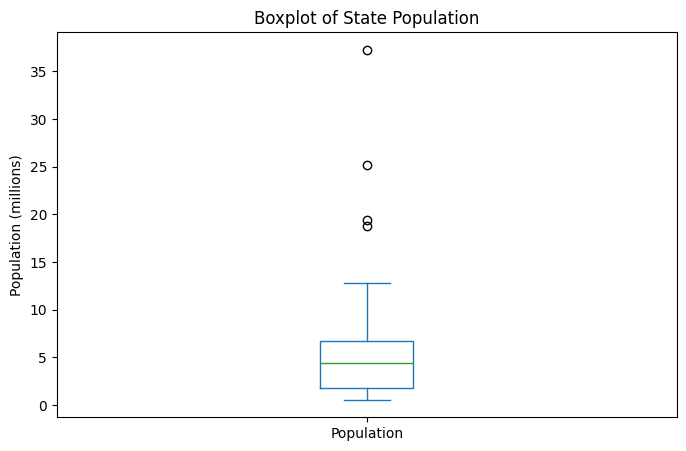

In [92]:
state = pd.read_csv("datasets/state.csv")

ax = (state["Population"] / 1_000_000).plot.box(
    figsize=(8, 5)
    )

ax.set_ylabel("Population (millions)")
plt.title("Boxplot of State Population")
plt.show()

#### 3.5.3 Code Explanation - Part 01

The `quantile()` method calculates selected percentiles of **`Murder.Rate`**, showing the values below which **5%**, **25%**, **50%**, **75%**, and **95%** of observations fall.

The 5th, 25th, 50th, 75th, and 95th percentiles **summarize the lower tail, lower quartile, median, upper quartile, and upper tail**, respectively. 

The `boxplot` **scales population in millions and displays the median, interquartile range, whiskers, and potential outliers**, providing a compact visual summary of state population variability.

#### 3.5.4 Result Analysis & Interpretation - Part 01

The calculated percentiles are **1.600**, **2.425**, **4.000**, **5.550**, and **6.510**, showing that the **`median` state murder rate** is **4.000 per 100,000 residents.** 

The **central 50%** of murder rates **lies between 2.425 and 5.550,** while the 5th-to-95th percentile range shows variation across states.

The population boxplot shows a `median` of approximately **4.4 million** residents, with half the states falling roughly between 2 and 7 million residents and several high-population outliers.

#### 3.5.2 Code Reproduction - Part 02

The implementation reproduces `frequency table` and `histogram` methods from the reference material using **state.csv** to analyze how state populations distribute across equal‑width intervals.

In [93]:
from IPython.display import display 

state = pd.read_csv("datasets/state.csv")

binned_population = pd.cut(state["Population"], bins=10) #divide to ten equal-width intervals
binned_population.name = "PopulationBin"

df = (
    pd.concat([state, binned_population], axis=1)
    .sort_values(by="Population")
)

groups = [] #structure of the frequency table
for bin_number, (interval, subset) in enumerate(
    df.groupby("PopulationBin", observed=False, sort=True),
    start=1
):
    count = len(subset)

    groups.append({
        "Bin": bin_number,
        "Population Interval": (
            f"({interval.left:,.0f}, {interval.right:,.0f}]"
        ),
        "Number of States": count,
        "State Abbreviations": (
            ", ".join(subset["Abbreviation"])
            if count > 0 else "-"
        )
    })

frequency_table = pd.DataFrame(groups)
max_frequency = frequency_table["Number of States"].max()

def describe_bin(row):
    if row["Number of States"] == 0:
        return "No states in this interval"

    notes = []

    if row["Bin"] == 1:
        notes.append("Lowest population interval")

    if row["Bin"] == 10:
        notes.append("Highest population interval")

    if row["Number of States"] == max_frequency:
        notes.append("Highest frequency")

    return "; ".join(notes) if notes else "-"

frequency_table["Distribution Note"] = frequency_table.apply(
    describe_bin, axis=1
)

display(
    frequency_table.style
    .format({
        "Bin": "{:02d}",
        "Number of States": "{:d}"
    })
    .set_table_styles([
    {
        "selector": "caption",
        "props": [("text-align", "center"), ("caption-side", "top")]
    },
    {
        "selector": "th",
        "props": [("text-align", "center")]
    }
])
    .set_caption(
        "Table Frequency Distribution of State Population"
    )
    .set_properties(**{"text-align": "center"})
    .set_properties(
        subset=["Bin", "Number of States"],
        **{"text-align": "center"}
    )
    .hide(axis="index")
)

Bin,Population Interval,Number of States,State Abbreviations,Distribution Note
01,"(526,936, 4,232,659]",24,"WY, VT, ND, AK, SD, DE, MT, RI, NH, ME, HI, ID, NE, WV, NM, NV, UT, KS, AR, MS, IA, CT, OK, OR",Lowest population interval; Highest frequency
02,"(4,232,659, 7,901,692]",14,"KY, LA, SC, AL, CO, MN, WI, MD, MO, TN, AZ, IN, MA, WA",-
03,"(7,901,692, 11,570,725]",6,"VA, NJ, NC, GA, MI, OH",-
04,"(11,570,725, 15,239,758]",2,"PA, IL",-
05,"(15,239,758, 18,908,791]",1,FL,-
06,"(18,908,791, 22,577,824]",1,NY,-
07,"(22,577,824, 26,246,857]",1,TX,-
08,"(26,246,857, 29,915,890]",0,-,No states in this interval
09,"(29,915,890, 33,584,923]",0,-,No states in this interval
10,"(33,584,923, 37,253,956]",1,CA,Highest population interval


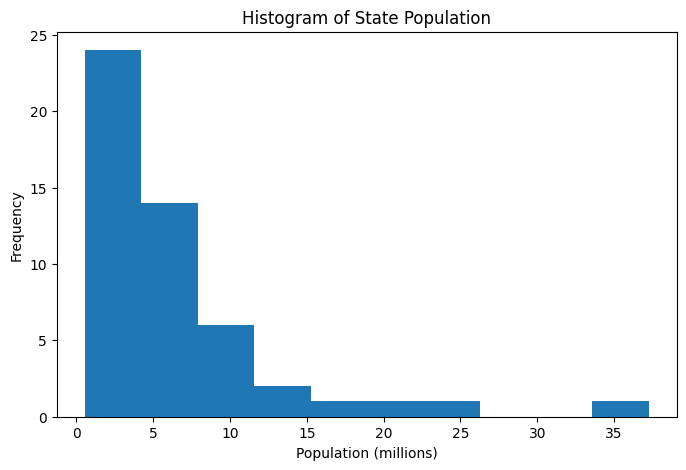

In [94]:
state = pd.read_csv("datasets/state.csv")

ax = (state["Population"] / 1_000_000).plot.hist(
    bins=10, 
    figsize=(8, 5)
    )

plt.title("Histogram of State Population")
ax.set_xlabel("Population (millions)")
ax.set_ylabel("Frequency")
plt.show()

#### 3.5.3 Code Explanation - Part 02

The `pd.cut()` function divides **`Population`** into **ten equal-width intervals**, allowing state populations to be grouped and summarized according to their ranges. 

The `frequency table` reports each interval’s state count and abbreviations, while the distribution notes identify empty intervals, the lowest and highest ranges, and the interval with the greatest frequency.

The `histogram` presents **population measured in millions and displays interval frequencies,** helping highlight concentration areas and assess skewness within the distribution.

#### 3.5.4 Result Analysis & Interpretation - Part 02

The `frequency table` contains 24 states in the first interval and 14 in the second, so **38 of the 50 states fall within the two lowest population ranges.**

After the first two intervals, counts are **6, 2, 1, 1, 1, 0, 0, and 1,** leaving the eighth and ninth intervals empty.

The `histogram` shows a **right-skewed distribution**, where numerous states possess relatively small populations, while a few states with very large populations extend the upper tail significantly.

#### 3.5.2 Code Reproduction - Part 03

The reproduced implementation integrates `histogram` and `kernel density estimation`, providing a smoothed visualization of **`Murder.Rate`** distribution derived from the **state.csv** dataset.

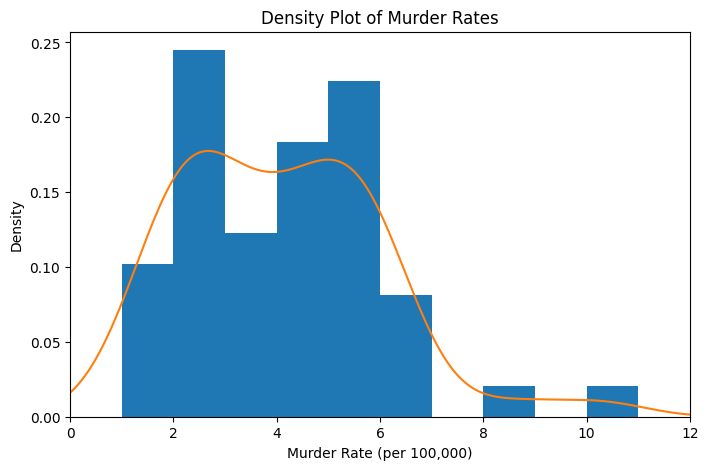

In [95]:
state = pd.read_csv("datasets/state.csv")

ax = state["Murder.Rate"].plot.hist(
    density=True,
    xlim=[0, 12],
    bins=range(1, 12),
    figsize=(8, 5)
)

state["Murder.Rate"].plot.density(ax=ax)
plt.title("Density Plot of Murder Rates")
ax.set_xlabel("Murder Rate (per 100,000)")
plt.show()

#### 3.5.3 Code Explanation - Part 03

The histogram's `density=True` argument **scales the bars as probability density rather than raw counts,** allowing direct comparison with the continuous density estimate. 

The `plot.density(ax=ax)` method **overlays a kernel density estimate on the existing histogram,** using the same axes to compare the smoothed curve with observed values. 

The `x-axis` **spans murder rates from zero to twelve per 100,000 residents,** while the `y-axis` **represents density rather than the number of states.**

#### 3.5.4 Result Analysis & Interpretation - Part 03

The `histogram` and `density curve` show the distribution of state murder rates, with most observations **concentrated in the lower-to-middle range** rather than at the extremes. 

The `median` is **4.000 murders per 100,000 residents,** while the **5th and 95th percentiles are 1.600 and 6.510,** indicating variation across states. 

The `density` curve smooths the `histogram` and highlights relative concentration, while its total area equals approximately one, so it represents a probability distribution rather than counts.

### 3.6 Exploring Binary and Categorical Data

#### 3.6.1 Concept Explanation

**Binary and categorical data** represents qualitative classifications, assigning observations into discrete categories rather than continuous scales, thereby focusing analysis on group membership instead of numerical measurement.

Binary variables contain two possible outcomes, while categorical variables may include several categories including flight delay causes, product classifications, or loan status indicators.

These variables are summarized using proportions, percentages, and the mode, each providing distinct perspectives on relative frequency, standardized frequency, and the most frequent category.

#### Mathematical Representation

The `proportion` measures the relative frequency of each category by comparing the number of observations within a category to the total observations:

$$
p_i = \frac{n_i}{N}
$$

$$
\text{Percentage}_i = \frac{n_i}{N}\times 100\%
$$

| Symbol | Description |
| :--- | :--- |
| $p_i$ | Proportion of category $i$ |
| $n_i$ | Frequency of category $i$ |
| $N$ | Total number of observations |


The `expected value` represents a weighted average where each possible outcome is multiplied by its probability of occurrence:

$$
EV = \sum_{i=1}^{k} x_i P(x_i)
$$

| Symbol | Description |
| :--- | :--- |
| $EV$ | Expected value |
| $x_i$ | Numerical value of outcome $i$ |
| $P(x_i)$ | Probability of outcome $i$ |
| $k$ | Number of possible outcomes |

#### 3.6.2 Code Reproduction - Part 01

The implementation reproduces categorical data exploration from the reference material using **dfw_airline.csv** to to calculate delay proportions and percentages across different causes.

In [96]:
dfw = pd.read_csv("datasets/dfw_airline.csv")

delays = dfw.to_numpy().sum() #calculate  total number of delays
percentage = (100 * dfw / delays).round(2) #convert to percentages
percentage.index = ["Percentage"]
percentage.style.format("{:.3f}%")

,Carrier,ATC,Weather,Security,Inbound
Percentage,23.020%,30.400%,4.030%,0.120%,42.430%


#### 3.6.3 Code Explanation - Part 01

The `pd.read_csv()` function imports the DFW delay dataset into a pandas `DataFrame`, where each column corresponds to a specific delay category such as **`Carrier`, **`ATC`**, **`Weather`**, **`Security`**, or **`Inbound`**.

The `to_numpy().sum()` operation computes the total number of delays across all categories, and dividing each category value by this total produces proportions, later converted into percentages by multiplying with one hundred.

The `round(2)` restricts numerical precision to two decimal places, while `style.format("{:.2f}%")` appends the percentage symbol, thereby improving readability without altering the underlying numerical values.

#### 3.6.4 Result Analysis & Interpretation - Part 01

The percentage distribution indicates that **`Inbound`** delays account for the largest share at **42.430%**, followed by **`ATC`** delays at **30.400%** and **`Carrier`** delays at **23.020%**.

**`Weather`** contributes **4.030%** of the recorded delays, while **`Security`** accounts for only **0.120%**, showing that inbound aircraft delays dominate the dataset compared with other categories.

**`Inbound`** therefore represents the mode of the categorical variable, and the percentage table provides a concise summary of relative contributions across all recorded delay categories.

#### 3.6.2 Code Reproduction - Part 02

The implementation visualizes categorical delay frequencies using a `bar chart` to **compare the contribution of each delay cause within the dataset.**

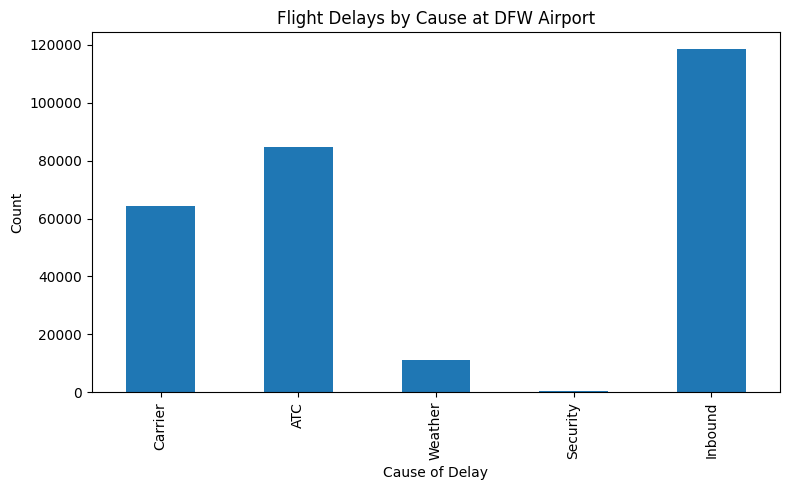

In [97]:

dfw = pd.read_csv("datasets/dfw_airline.csv")

ax = dfw.transpose().plot.bar(
    figsize=(8,5),
    legend=False
)

ax.set_xlabel("Cause of Delay")
ax.set_ylabel("Count")
ax.set_title("Flight Delays by Cause at DFW Airport")

plt.tight_layout()
plt.show()

#### 3.6.3 Code Explanation - Part 02

The `transpose()` function converts the `DataFrame` structure so that delay causes become individual categories displayed along the horizontal axis.

The `plot.bar()` method creates a bar chart where each bar shows delay values per category, with `figsize` adjusting dimensions and `legend=False` removing redundant legends.

Axis labels and chart title emphasize that the visualization compares categorical delay values, distinguishing bar charts from histograms used for numerical distributions.

#### 3.6.4 Result Analysis & Interpretation - Part 02

The bar chart illustrates differences in recorded delay values across five categories, with **`Inbound`** delays **highest at 42.43%** and **`Security`** delays **lowest at only 0.12%.**

This visualization makes **categorical differences easier to identify than numerical tables,** though the vertical scale represents recorded values rather than percentages and should not be misinterpreted.

Comparing the percentage table and bar chart shows categorical data can be summarized both numerically and visually, with each representation serving distinct analytical purposes in interpretation.

### 3.7 Correlation

#### 3.7.1 Concept Explanation

**Correlation** is a statistical method measuring relationships between numerical variables, helping exploratory data analysis identify associations between changes in one variable and another.

**Positive correlation** occurs when high values align across variables, while **negative correlation** arises when high values align with low values, measured on a scale ranging from **-1 to +1.**

A **correlation matrix** shows pairwise coefficients and **scatterplots** reveal variable patterns, but correlation only identifies associations, not causation, and may fail with nonlinear relationships or outliers.

#### Mathematical Representation

Pearson's `correlation coefficient` expresses standardized covariance between paired observations, defined mathematically as the sum of products of deviations from means divided by the product of sample standard deviations:

$$
r =
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
(n-1)s_xs_y
}
$$

| Symbol | Description |
| :--- | :--- |
| $r$ | Pearson correlation coefficient |
| $x_i$ | Observation of variable $X$ |
| $y_i$ | Observation of variable $Y$ |
| $\bar{x}$ | Mean of variable $X$ |
| $\bar{y}$ | Mean of variable $Y$ |
| $s_x$ | Sample standard deviation of variable $X$ |
| $s_y$ | Sample standard deviation of variable $Y$ |
| $n$ | Number of paired observations |

#### 3.7.2 Code Reproduction - Part 01

The implementation reproduces correlation analysis using **sp500_sectors.csv** and **sp500_data.csv.gz**, selecting telecommunications stocks from July 2012 onward to compute their correlation matrix.

In [102]:
sp500_sym = pd.read_csv("datasets/sp500_sectors.csv")
sp500_px = pd.read_csv(
    "datasets/sp500_data.csv.gz",
    index_col=0,
    parse_dates=True
)

telecomSymbols = sp500_sym[
    sp500_sym['sector'] == 'telecommunications_services'
]['symbol'].tolist()

telecom = sp500_px.loc[
    (sp500_px.index >= '2012-07-01') &
    (sp500_px.index <= '2015-06-30'),
    telecomSymbols
] # filter data from July 2012 through June 2015

telecomCorrelation = telecom.corr() #calculate the correlation matrix
telecomCorrelation.round(3) #display the correlation matrix rounded to 3 decimal places

,T,CTL,FTR,VZ,LVLT
T,1.000,0.475,0.328,0.678,0.279
CTL,0.475,1.000,0.420,0.417,0.287
FTR,0.328,0.420,1.000,0.288,0.260
VZ,0.678,0.417,0.288,1.000,0.242
LVLT,0.279,0.287,0.260,0.242,1.000


#### 3.7.3 Code Explanation - Part 01

The `pd.read_csv()` function imports sector classifications and daily stock‑return data into **pandas `DataFrame`** objects, assigning observation dates as index for structured time‑series analysis.

The `.loc[]` method filters telecommunications stocks and restricts observations beginning July 2012, thereby producing a dataset consistent with the analytical scope. 

The `corr()` method then computes pairwise Pearson correlation coefficients, and `round(3)` displays results to three decimals, generating a correlation matrix that facilitates interpretation and comparison across selected variables.

#### 3.7.4 Result Analysis & Interpretation - Part 01

The `correlation matrix` demonstrates that all telecommunications stocks exhibit positive pairwise correlations, indicating their returns generally move in the same direction during the observed period. 

The **strongest** association occurs **between AT&T and Verizon**, with a coefficient of 0.678, while Level 3 shows weaker relationships with other stocks. 

**Diagonal entries** equal **1.000** due to perfect self‑correlation, and matrix symmetry ensures identical values regardless of variable order, emphasizing statistical association rather than causal inference.

#### 3.7.2 Code Reproduction - Part 02

This implementation constructs a `heatmap` of **ETF correlations**, illustrating positive and negative relationships among instruments to facilitate clearer interpretation of their statistical associations.

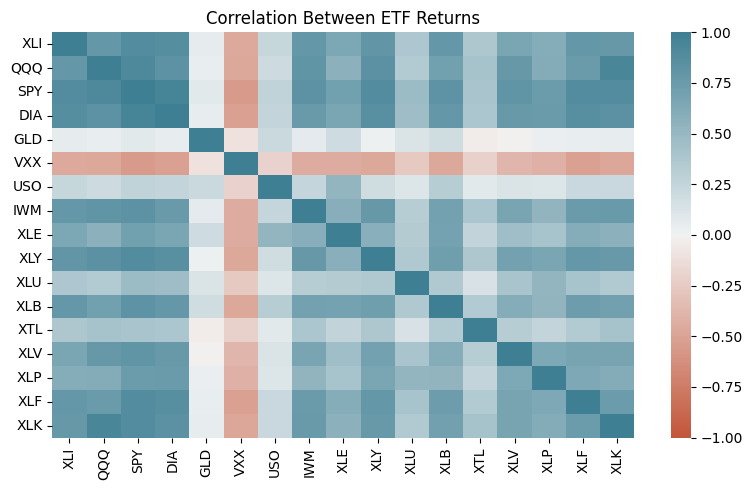

In [104]:
etfSymbols = sp500_px.loc[
    sp500_px.index > "2012-07-01",
    sp500_sym.loc[
        sp500_sym["sector"] == "etf",
        "symbol"
    ]
]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    etfs.corr(),
    vmin=-1,
    vmax=1,
    cmap=sns.diverging_palette(20, 220, as_cmap=True),
    ax=ax
)

ax.set_title("Correlation Between ETF Returns")
plt.tight_layout()
plt.show()

#### 3.7.3 Code Explanation - Part 02

The code selects **ETF symbols** from the classification dataset and extracts their corresponding observations from `sp500_px`, focusing on data recorded after July 2012 for analysis. 

The `corr()` method computes pairwise correlations among the selected ETFs, while `sns.heatmap()` transforms the resulting matrix into a **color‑coded visualization** bounded between −1 and +1. 

The diverging color palette highlights positive and negative relationships, producing a compact heatmap that summarizes statistical associations among the chosen exchange‑traded funds effectively.

#### 3.7.4 Result Analysis & Interpretation - Part 02

The `heatmap` enables visual comparison of correlations among ETFs, showing strong positive relationships between broad‑market funds such as **SPY** and **DIA** that track overall US equity performance.

Similarly, **QQQ** and **XLK** exhibit positive associations because both emphasize technology‑related investments, reflecting overlapping exposure to major technology companies within their portfolios. 

In contrast, defensive or alternative ETFs like **GLD**, **USO**, and **VXX** display weaker or negative correlations, illustrating diversification opportunities and emphasizing that historical associations do not guarantee future persistence.

#### 3.7.2 Code Reproduction - Part 03

This implementation uses a **scatterplot** to examine the relationship between AT&T (`T`) and Verizon (`VZ`) stock returns. Each point represents an observation for the two stocks, allowing their direction of association and overall distribution to be examined visually.

### 3.8 Exploring Two or More Variables

## 4. Discussion & Conclusion